# Get information from Genbank

In [31]:
# Optional post-processing for pandas DataFrame:
# Keep one best (highest-quality) GenBank assembly per species,
# optionally requiring annotation and minimum assembly level.

# Ranking: higher is better
ASSEMBLY_RANK = {
    "Complete Genome": 4,
    "Chromosome": 3,
    "Scaffold": 2,
    "Contig": 1
}


def filter_and_select_best_assembly_df(
    df,
    min_level="Scaffold",
    require_annotation=True
):
    """
    Collapse to one representative assembly per species.

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain columns:
            - species
            - assembly_level
            - annotation_status
    min_level : str
        Minimum assembly quality to retain:
        Complete Genome / Chromosome / Scaffold / Contig
    require_annotation : bool
        Keep only annotated genomes.

    Returns
    -------
    pandas.DataFrame
        Best assembly per species.
    """

    df = df.copy()

    # Add numeric rank column
    df["assembly_rank"] = df["assembly_level"].map(ASSEMBLY_RANK).fillna(0)

    # Filter by minimum assembly level
    min_rank = ASSEMBLY_RANK.get(min_level, 2)
    df = df[df["assembly_rank"] >= min_rank]

    # Filter annotated genomes if requested
    if require_annotation:
        df = df[
            df["annotation_status"].astype(str).str.lower().isin(
                ["true", "1", "yes"]
            )
        ]

    # Sort so best assemblies come first
    df = df.sort_values(
        by=["species", "assembly_rank"],
        ascending=[True, False]
    )

    # Keep best assembly per species
    df_best = df.drop_duplicates(
        subset="species",
        keep="first"
    )

    # Remove helper column
    df_best = df_best.drop(columns=["assembly_rank"])

    # Optional: reset index
    df_best = df_best.reset_index(drop=True)

    return df_best

def reshape_gene_prevalence(df):
    """
    Convert wide prevalence table into long format.

    Input columns example:
        order, count, BST2_count, BST2_ratio, DRAM1_count, DRAM1_ratio

    Output:
        order, count, gene_name, gene_count, ratio
    """

    # Find gene names from *_count columns (excluding total count)
    gene_names = [
        col.replace("_count", "")
        for col in df.columns
        if col.endswith("_count") and col != "count"
    ]

    long_dfs = []

    for gene in gene_names:
        temp = df[["order", "count"]].copy()
        temp["gene_name"] = gene
        temp["species_count"] = df[f"{gene}_count"]
        temp["total_gene_copies"] = df[f"{gene}_total_copies"]
        temp["mean_gene_copies"] = df[f"{gene}_mean_copies"]

        long_dfs.append(temp)

    df_long = pd.concat(long_dfs, ignore_index=True)

    return df_long

In [2]:
def add_gene_prevalence_from_folder(df_order, input_folder):
    """
    For each gene subfolder in input_folder:
      - find file ending with 'one_isoform.tsv'
      - read it
      - remove duplicate species
      - count species per mammalian order
      - merge counts into df_order
      - calculate prevalence ratio

    Parameters
    ----------
    df_order : pd.DataFrame
        Must contain:
            - order
            - count   (total species/genomes per order)

    input_folder : str
        Parent folder containing gene subfolders
        Example:
            final_metazoa_phylogenies/
                BST2/
                    261_BST2_mammalia_one_isoform.tsv
                DRAM1/
                    225_DRAM1_mammalia_one_isoform.tsv

    Returns
    -------
    pd.DataFrame
        Updated df_order with gene counts and ratios
    """

    df_order = df_order.copy()

    # find all matching files recursively
    pattern = os.path.join(input_folder, "*", "*one_isoform.tsv")
    gene_files = glob.glob(pattern)

    if not gene_files:
        print(f"No one_isoform.tsv files found in {input_folder}")
        return df_order

    for file_gene in gene_files:
        try:
            df_gene = pd.read_csv(file_gene, sep="\t")
        except Exception as e:
            print(f"Skipping {file_gene}: {e}")
            continue

        # infer gene name from filename
        filename = os.path.basename(file_gene)
        parts = filename.split("_")

        if len(parts) < 2:
            print(f"Could not infer gene name from {filename}")
            continue

        gene = parts[1]

        # require needed columns
        if "species" not in df_gene.columns or "order" not in df_gene.columns:
            print(f"Skipping {file_gene}: missing species/order columns")
            continue

        # remove duplicate species
        df_gene = df_gene.drop_duplicates(subset="species")

        # count species with ortholog per order
        df_gene_order = (
            df_gene["order"]
            .value_counts()
            .reset_index()
        )
        df_gene_order.columns = ["order", f"{gene}_count"]

        # merge into master df
        df_order = df_order.merge(
            df_gene_order,
            how="left",
            on="order"
        )

        # fill missing counts with 0
        #df_order[f"{gene}_count"] = df_order[f"{gene}_count"].fillna(0)

        # calculate ratio
        df_order[f"{gene}_ratio"] = round(
            df_order[f"{gene}_count"] / df_order["count"],
            2
        )

    return df_order

# Add tree annotations to the one isoform tables

In [27]:
import os
import glob
import pandas as pd

In [48]:
#file = "angry_gene_gains_and_losses/protein_tables/199_TTC39B_mammalia_one_isoform.tsv"
#df['curated_gene_name'] = 'TTC39B'
file = "angry_gene_gains_and_losses/protein_tables/309_PLSCR_mammalia_one_isoform.tsv"
df = pd.read_csv(file, sep='\t')
df['curated_gene_name'] = 'PLSCR'
df.to_csv(file, index=False, sep='\t')

In [62]:
def assign_gene_name(df, protein_ids, gene_name, col='curated_gene_name', id_col='protein_id'):
    if col not in df.columns:
        df[col] = None
    mask = df[id_col].isin(protein_ids) & df[col].isna()
    df.loc[mask, col] = gene_name

def find_tsv_for_gene(gene_name, tsv_folder):
    """Find TSV file(s) whose filename contains the gene name."""
    matches = glob.glob(os.path.join(tsv_folder, f"*{gene_name}*.tsv"))
    return matches

In [ ]:
# Folders
txt_folder = "../additional_files/gene_expansions_and_losses/protein_ids"
tsv_folder = "../additional_files/gene_expansions_and_losses/protein_tables"

# Track modified TSVs to avoid redundant reads/writes
tsv_cache = {}

# Process all txt files
for txt_file in glob.glob(os.path.join(txt_folder, "*.txt")):
    filename = os.path.basename(txt_file)
    parts = filename.split('_')
    
    gene_number = int(parts[0])
    gene_name = parts[1]

    # Read protein IDs
    with open(txt_file, 'r') as f:
        protein_ids = [line.strip() for line in f if line.strip()]

    # Validate count
    if len(protein_ids) != gene_number:
        print(f"WARNING [{filename}]: expected {gene_number} IDs, got {len(protein_ids)}")

    # Find matching TSV(s) — could be more than one if gene appears in multiple filenames
    tsv_matches = find_tsv_for_gene(gene_name, tsv_folder)
    
    if not tsv_matches:
        print(f"WARNING [{filename}]: no TSV found containing '{gene_name}'")
        continue

    for tsv_file in tsv_matches:
        # Use cache to avoid re-reading a TSV already loaded in this run
        if tsv_file not in tsv_cache:
            tsv_cache[tsv_file] = pd.read_csv(tsv_file, sep='\t')
        
        assign_gene_name(tsv_cache[tsv_file], protein_ids, gene_name)
        print(f"OK: '{gene_name}' -> {os.path.basename(tsv_file)}")

# Write all modified TSVs once at the end
for tsv_file, df in tsv_cache.items():
    df.to_csv(tsv_file, index=False, sep='\t')
    print(f"Saved: {tsv_file}")

# Calculate orthologue prevalence in Mammalian orders

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import glob

In [ ]:
# Calculates gene copy mean per order (works with grouping of orders into higher clades, eg. Marsupials or Afrotheria)
def add_gene_prevalence_from_folder(df_order, input_folder, grouping=None):
    df_order = df_order.copy()
    known_orders = set(df_order["order"])

    order_to_group = {}
    if grouping:
        for group_label, orders in grouping.items():
            for o in orders:
                if o not in known_orders:
                    order_to_group[o] = group_label

    def remap_orders(series):
        return series.map(lambda o: order_to_group.get(o, o))

    pattern = os.path.join(input_folder, "*one_isoform.tsv")
    gene_files = glob.glob(pattern)

    if not gene_files:
        print(f"No one_isoform.tsv files found in {input_folder}")
        return df_order

    for file_gene in gene_files:
        try:
            df_gene = pd.read_csv(file_gene, sep="\t")
        except Exception as e:
            print(f"Skipping {file_gene}: {e}")
            continue

        filename = os.path.basename(file_gene)

        required = {"species", "order", "curated_gene_name"}
        if not required.issubset(df_gene.columns):
            missing = required - set(df_gene.columns)
            print(f"Skipping {filename}: missing columns {missing}")
            continue

        df_gene = df_gene.dropna(subset=["curated_gene_name"])
        if df_gene.empty:
            print(f"Skipping {filename}: no curated_gene_name values found")
            continue

        df_gene = df_gene.copy()
        df_gene["order"] = remap_orders(df_gene["order"])

        for gene, df_gene_group in df_gene.groupby("curated_gene_name"):

            # --- Per-order stats in one groupby pass ---
            order_stats = df_gene_group.groupby("order")["species"].agg(
                total_copies="count",       # total gene copies (rows)
                species_with_gene="nunique" # number of distinct species
            ).reset_index()

            # Mean copies per species = total copies / species with the gene
            order_stats[f"{gene}_mean_copies"] = round(
                order_stats["total_copies"] / order_stats["species_with_gene"], 2
            )

            order_stats = order_stats.rename(columns={
                "total_copies":       f"{gene}_total_copies",  # kept for reference
                "species_with_gene":  f"{gene}_count",         # NEW: species count
            })

            df_order = df_order.merge(
                order_stats[["order", f"{gene}_total_copies",
                             f"{gene}_count", f"{gene}_mean_copies"]],
                how="left",
                on="order"
            )

    return df_order

In [ ]:
file_assemblies = "../additional_files/ncbi_mammalian_genome_assemblies/mammalian_genbank_assemblies.tsv"
df_assemblies = pd.read_csv(file_assemblies, sep='\t')

df_assemblies_best = filter_and_select_best_assembly_df(
    df_assemblies,
    min_level="Scaffold",
    require_annotation=False
)

df_order = df_assemblies_best['order'].value_counts().reset_index()

In [41]:
# ── Define your groupings ──────────────────────────────────────────────────────
# Any order NOT listed here keeps its own name as the group label.
grouping = {
    # Marsupials
    'Marsupialia': ['Diprotodontia', 'Dasyuromorphia', 'Didelphimorphia',
                    'Peramelemorphia', 'Microbiotheria', 'Paucituberculata',
                    'Notoryctemorphia'],
    # Xenarthrans
    'Xenarthra':   ['Pilosa', 'Cingulata'],
    # Afrotherians
    'Afrotheria':  ['Afrosoricida', 'Sirenia', 'Proboscidea',
                    'Macroscelidea', 'Hyracoidea', 'Tubulidentata'],
    # Tree shrews + colugos (sometimes grouped as Euarchonta base)
    #'Euarchonta_basal': ['Dermoptera', 'Scandentia'],
}

# ── Build a lookup: order → group label ───────────────────────────────────────
order_to_group = {}
for group_label, orders in grouping.items():
    for o in orders:
        order_to_group[o] = group_label

df_order['group'] = df_order['order'].map(order_to_group).fillna(df_order['order'])

# ── Collapse: sum counts within each group ────────────────────────────────────
df_collapsed = (
    df_order.groupby('group', sort=False)['count']
    .sum()
    .reset_index()
    .rename(columns={'group': 'order'})
    .sort_values('count', ascending=False)
    .reset_index(drop=True)
)

In [ ]:
df_order_updated = add_gene_prevalence_from_folder(df_order, "../additional_files/gene_expansions_and_losses/protein_tables")

In [21]:
df_order_updated.columns

Index(['order', 'count', 'group', 'PARP12_total_copies', 'PARP12_count',
       'PARP12_mean_copies', 'IFI6_total_copies', 'IFI6_count',
       'IFI6_mean_copies', 'IFIT1_total_copies',
       ...
       'BTN3_mean_copies', 'RNF213_total_copies', 'RNF213_count',
       'RNF213_mean_copies', 'RNF19B_total_copies', 'RNF19B_count',
       'RNF19B_mean_copies', 'HAS3_total_copies', 'HAS3_count',
       'HAS3_mean_copies'],
      dtype='object', length=105)

In [13]:
df_order_updated[['order','count','IFITM_count']]

,order,count,IFITM_count
0,Primates,251,38.0
1,Artiodactyla,193,35.0
2,Rodentia,168,42.0
3,Chiroptera,118,21.0
4,Carnivora,114,42.0
5,Eulipotyphla,23,5.0
6,Perissodactyla,17,4.0
7,Lagomorpha,16,1.0
8,Diprotodontia,16,2.0
9,Dasyuromorphia,9,1.0


In [ ]:
df_order_updated = add_gene_prevalence_from_folder(
    df_collapsed,
    "../additional_files/gene_expansions_and_losses/protein_tables",
    grouping=grouping          # the same dict you defined earlier
)

In [43]:
df_order_updated[['order','count','IFITM_count', 'IFITM_total_copies', 'IFITM_mean_copies']]

,order,count,IFITM_count,IFITM_total_copies,IFITM_mean_copies
0,Primates,251,38,81,2.13
1,Artiodactyla,193,35,77,2.20
2,Rodentia,168,42,131,3.12
3,Chiroptera,118,21,111,5.29
4,Carnivora,114,42,122,2.90
5,Marsupialia,32,5,8,1.60
6,Eulipotyphla,23,5,14,2.80
7,Afrotheria,19,5,17,3.40
8,Perissodactyla,17,4,13,3.25
9,Lagomorpha,16,1,2,2.00


In [ ]:
df_order_updated = add_gene_prevalence_from_folder(
    df_collapsed,
    "../additional_files/gene_expansions_and_losses/protein_tables",
    grouping=grouping          # the same dict you defined earlier
)

In [30]:
df_order_updated.iloc[:,:15]

,order,count,PARP12_total_copies,PARP12_count,PARP12_mean_copies,IFI6_total_copies,IFI6_count,IFI6_mean_copies,IFIT1_total_copies,IFIT1_count,IFIT1_mean_copies,IFIT1B_total_copies,IFIT1B_count,IFIT1B_mean_copies,ZC3HAV1_total_copies
0,Primates,251,31.0,31.0,1.0,29.0,29.0,1.0,28.0,28.0,1.00,17.0,17.0,1.00,40.0
1,Artiodactyla,193,36.0,36.0,1.0,34.0,34.0,1.0,35.0,35.0,1.00,NaN,NaN,NaN,38.0
2,Rodentia,168,42.0,42.0,1.0,NaN,NaN,NaN,13.0,10.0,1.30,94.0,41.0,2.29,41.0
3,Chiroptera,118,20.0,20.0,1.0,19.0,19.0,1.0,32.0,18.0,1.78,NaN,NaN,NaN,19.0
4,Carnivora,114,39.0,39.0,1.0,29.0,29.0,1.0,34.0,33.0,1.03,25.0,25.0,1.00,42.0
5,Marsupialia,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Eulipotyphla,23,7.0,7.0,1.0,NaN,NaN,NaN,8.0,4.0,2.00,NaN,NaN,NaN,6.0
7,Afrotheria,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Perissodactyla,17,6.0,6.0,1.0,3.0,3.0,1.0,4.0,2.0,2.00,3.0,3.0,1.00,6.0
9,Lagomorpha,16,2.0,2.0,1.0,NaN,NaN,NaN,6.0,3.0,2.00,5.0,3.0,1.67,2.0


In [50]:
df_order_updated = df_order_updated[
    df_order_updated["order"] != "Afrosoricida"
]

In [44]:
# Example usage
df_long = reshape_gene_prevalence(df_order_updated)

In [45]:
df_long['order_label'] = df_long['order'] + " (" + df_long['count'].astype(str) + ")"

In [46]:
df_long.drop_duplicates(subset='order')

,order,count,gene_name,species_count,total_gene_copies,mean_gene_copies,order_label
0,Primates,251,PARP12,31.0,31.0,1.0,Primates (251)
1,Artiodactyla,193,PARP12,36.0,36.0,1.0,Artiodactyla (193)
2,Rodentia,168,PARP12,42.0,42.0,1.0,Rodentia (168)
3,Chiroptera,118,PARP12,20.0,20.0,1.0,Chiroptera (118)
4,Carnivora,114,PARP12,39.0,39.0,1.0,Carnivora (114)
5,Marsupialia,32,PARP12,8.0,8.0,1.0,Marsupialia (32)
6,Eulipotyphla,23,PARP12,7.0,7.0,1.0,Eulipotyphla (23)
7,Afrotheria,19,PARP12,5.0,5.0,1.0,Afrotheria (19)
8,Perissodactyla,17,PARP12,6.0,6.0,1.0,Perissodactyla (17)
9,Lagomorpha,16,PARP12,2.0,2.0,1.0,Lagomorpha (16)


In [47]:
'''
custom_order = [
    'Primates',
    'Dermoptera',
    'Scandentia',
    'Rodentia',
    'Lagomorpha',
    'Pholidota',
    'Carnivora',
    'Perissodactyla',
    'Artiodactyla',
    'Chiroptera',
    'Eulipotyphla',
    'Sirenia',
    'Proboscidea',
    'Hyracoidea',
    'Tubulidentata',
    'Macroscelidea',
    'Pilosa',
    'Cingulata',
    'Peramelemorphia',
    'Dasyuromorphia',
    'Notoryctemorphia',
    'Diprotodontia',
    'Microbiotheria',
    'Paucituberculata',
    'Didelphimorphia',
    'Monotremata',
]
'''
custom_order = [
    'Primates',
    'Dermoptera',
    'Scandentia',
    'Rodentia',
    'Lagomorpha',
    'Pholidota',
    'Carnivora',
    'Perissodactyla',
    'Artiodactyla',
    'Chiroptera',
    'Eulipotyphla',
    'Afrotheria',
    'Xenarthra',
    'Marsupialia',
    'Monotremata',
]

# Set ordered categorical
df_long["order"] = pd.Categorical(
    df_long["order"],
    categories=custom_order,
    ordered=True
)

In [48]:
'''
custom_label_order = [
    'Primates (251)',
    'Dermoptera (2)',
    'Scandentia (2)',
    'Rodentia (168)',
    'Lagomorpha (16)',
    'Pholidota (8)',
    'Carnivora (114)',
    'Perissodactyla (17)',
    'Artiodactyla (193)',
    'Chiroptera (118)',
    'Eulipotyphla (23)',
    'Sirenia (4)',
    'Proboscidea (4)',
    'Hyracoidea (2)',
    'Tubulidentata (2)',
    'Macroscelidea (2)',
    'Pilosa (6)',
    'Cingulata (4)',
    'Peramelemorphia (2)',
    'Dasyuromorphia (9)',
    'Notoryctemorphia (1)',
    'Diprotodontia (16)',
    'Microbiotheria (1)',
    'Paucituberculata (1)',
    'Didelphimorphia (2)',
    'Monotremata (2)',
]
'''

custom_label_order = [
    'Primates (251)',
    'Dermoptera (2)',
    'Scandentia (2)',
    'Rodentia (168)',
    'Lagomorpha (16)',
    'Pholidota (8)',
    'Carnivora (114)',
    'Perissodactyla (17)',
    'Artiodactyla (193)',
    'Chiroptera (118)',
    'Eulipotyphla (23)',
    'Afrotheria (19)',
    'Xenarthra (10)',
    'Marsupialia (32)',
    'Monotremata (2)',
]

df_long["order_label"] = pd.Categorical(
    df_long["order_label"],
    categories=custom_label_order,
    ordered=True
)

#df_long.rename(columns={
#    'gene_count': 'species_count'
#}, inplace=True)

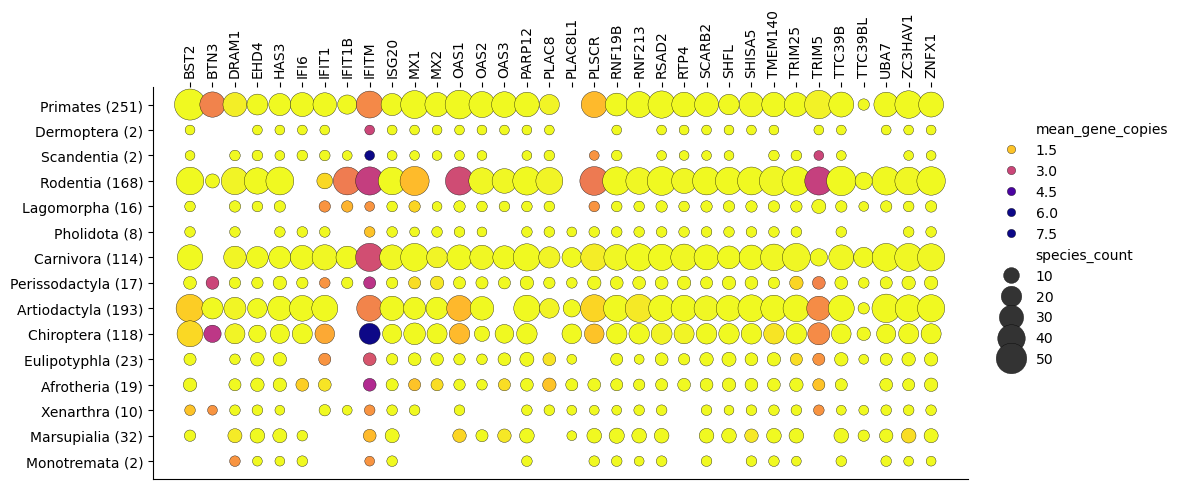

In [ ]:
g = sns.relplot(
    data=df_long.sort_values(by='gene_name'),
    x="gene_name",
    y="order_label",
    size="species_count",
    hue="mean_gene_copies",
    sizes=(50, 500),
    palette="plasma_r",
    height=5,
    aspect=2,
    edgecolor="black",
    linewidth=0.25,
    hue_norm=(1, 5)
)

ax = g.ax

# Remove axis labels
ax.set_xlabel("")
ax.set_ylabel("")

# Move x-axis ticks to top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Add grid
#ax.grid(axis="x", linestyle="--", alpha=0.2)

# Rotate x tick labels
plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center"
)

# Optional: improve spacing
g.tight_layout()

plt.savefig('../figures/all_isgs_species_count_and_gene_copy_number_with_grouping.svg', format='svg', bbox_inches='tight')

plt.show()

# Number of gene copies per species

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import glob

In [28]:
def build_species_gene_table(input_folder):
    """
    Reads all one_isoform.tsv files in input_folder and builds a table
    with one row per species and one column per gene (presence count).

    Parameters
    ----------
    input_folder : str
        Folder containing one_isoform.tsv files directly.

    Returns
    -------
    pd.DataFrame
        Columns: class, order, family, genus, species, <gene>_count, ...
    """

    taxonomy_cols = ["class", "order", "family", "genus", "species"]
    required_cols = set(taxonomy_cols + ["curated_gene_name"])

    pattern = os.path.join(input_folder, "*one_isoform.tsv")
    gene_files = glob.glob(pattern)

    if not gene_files:
        print(f"No one_isoform.tsv files found in {input_folder}")
        return pd.DataFrame()

    # accumulate one small pivot per gene across all files
    gene_counts = {}  # gene_name -> pd.Series indexed by species

    # collect taxonomy lookup: species -> {class, order, family, genus}
    taxonomy_lookup = {}

    for file_gene in gene_files:
        filename = os.path.basename(file_gene)
        try:
            df = pd.read_csv(file_gene, sep="\t")
        except Exception as e:
            print(f"Skipping {filename}: {e}")
            continue

        missing = required_cols - set(df.columns)
        if missing:
            print(f"Skipping {filename}: missing columns {missing}")
            continue

        df = df.dropna(subset=["curated_gene_name", "species"])
        if df.empty:
            continue

        # update taxonomy lookup from this file
        for _, row in df.drop_duplicates(subset="species").iterrows():
            if row["species"] not in taxonomy_lookup:
                taxonomy_lookup[row["species"]] = {
                    col: row.get(col, None) for col in taxonomy_cols if col != "species"
                }

        # count occurrences of each gene per species
        for gene, group in df.groupby("curated_gene_name"):
            counts = group.groupby("species").size()
            # accumulate across files (same gene can appear in multiple TSVs)
            if gene in gene_counts:
                gene_counts[gene] = gene_counts[gene].add(counts, fill_value=0)
            else:
                gene_counts[gene] = counts

    if not gene_counts:
        print("No curated_gene_name data found across all files.")
        return pd.DataFrame()

    # build taxonomy base table
    df_taxonomy = pd.DataFrame.from_dict(taxonomy_lookup, orient="index")
    df_taxonomy.index.name = "species"
    df_taxonomy = df_taxonomy.reset_index()

    # merge each gene's counts as a column
    for gene, counts in sorted(gene_counts.items()):
        df_gene_col = counts.rename(f"{gene}_count").reset_index()
        df_taxonomy = df_taxonomy.merge(df_gene_col, on="species", how="left")

    # leave species with no record for a gene as NaN
    gene_count_cols = [f"{gene}_count" for gene in gene_counts]

    # sort columns: taxonomy first, then genes alphabetically
    df_taxonomy = df_taxonomy[taxonomy_cols + sorted(gene_count_cols)]

    # sort rows by taxonomy
    df_taxonomy = df_taxonomy.sort_values(taxonomy_cols).reset_index(drop=True)

    return df_taxonomy

In [9]:
def melt_species_gene_table(df_species):
    """
    Transforms wide species-gene table into long format for seaborn plotting.

    Parameters
    ----------
    df_species : pd.DataFrame
        Output of build_species_gene_table(), with taxonomy columns
        and <gene>_count columns.

    Returns
    -------
    pd.DataFrame
        Columns: class, order, family, genus, species, gene, count
    """

    taxonomy_cols = ["class", "order", "family", "genus", "species"]
    gene_count_cols = [col for col in df_species.columns if col.endswith("_count")]

    df_long = df_species.melt(
        id_vars=taxonomy_cols,
        value_vars=gene_count_cols,
        var_name="gene",
        value_name="count"
    )

    # strip the '_count' suffix from gene names
    df_long["gene"] = df_long["gene"].str.replace("_count$", "", regex=True)

    return df_long.sort_values(taxonomy_cols).reset_index(drop=True)

In [ ]:
df_gene_copies = build_species_gene_table("../additional_files/gene_expansions_and_losses/protein_tables")

In [30]:
df_gene_copies[df_gene_copies['class']=='Mammalia']

,class,order,family,genus,species,BST2_count,BTN3_count,DRAM1_count,EHD4_count,HAS3_count,...,SHFL_count,SHISA5_count,TMEM140_count,TRIM25_count,TRIM5_count,TTC39BL_count,TTC39B_count,UBA7_count,ZC3HAV1_count,ZNFX1_count
0,Mammalia,Artiodactyla,Balaenopteridae,Balaenoptera,Balaenoptera acutorostrata,NaN,1.0,1.0,1.0,1.0,...,1.0,NaN,1.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0
1,Mammalia,Artiodactyla,Balaenopteridae,Balaenoptera,Balaenoptera musculus,1.0,1.0,2.0,1.0,1.0,...,1.0,1.0,1.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0
2,Mammalia,Artiodactyla,Balaenopteridae,Balaenoptera,Balaenoptera physalus,NaN,NaN,1.0,1.0,1.0,...,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
3,Mammalia,Artiodactyla,Bovidae,Bison,Bison bison,1.0,NaN,NaN,1.0,NaN,...,1.0,NaN,1.0,1.0,3.0,NaN,NaN,1.0,1.0,1.0
4,Mammalia,Artiodactyla,Bovidae,Bos,Bos grunniens,4.0,NaN,1.0,NaN,1.0,...,1.0,1.0,NaN,1.0,3.0,NaN,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,Mammalia,Scandentia,Tupaiidae,Tupaia,Tupaia chinensis,1.0,NaN,1.0,1.0,NaN,...,1.0,NaN,1.0,1.0,3.0,NaN,1.0,NaN,1.0,1.0
305,Mammalia,Sirenia,Trichechidae,Trichechus,Trichechus manatus,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0
306,Mammalia,Tubulidentata,Orycteropodidae,Orycteropus,Orycteropus afer,1.0,NaN,1.0,1.0,1.0,...,1.0,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN,1.0
307,Mammalia,NaN,Chrysochloridae,Chrysochloris,Chrysochloris asiatica,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,2.0,NaN,1.0,1.0,1.0,1.0


In [31]:
df_gene_copies_melted = melt_species_gene_table(df_gene_copies)

In [32]:
df_gene_copies_melted['count'].describe()

count    5716.000000
mean        1.187019
std         0.802127
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        17.000000
Name: count, dtype: float64

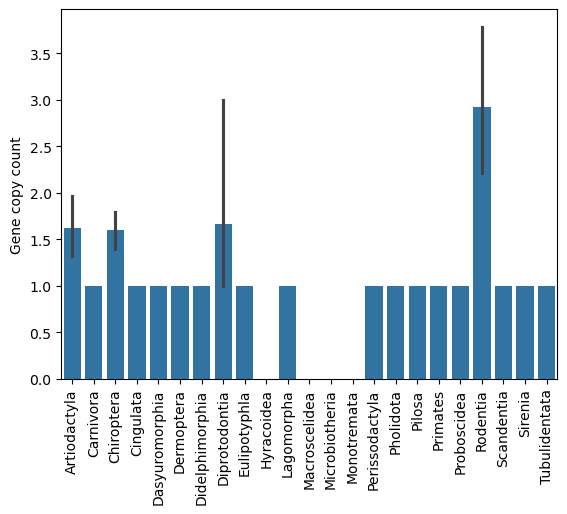

In [34]:
sns.barplot(df_gene_copies_melted[df_gene_copies_melted['gene']=='OAS1'], x='order', y='count')
plt.ylabel('Gene copy count')
plt.xlabel('')
plt.xticks(rotation=90, ha='center')
plt.show()

In [35]:
def plot_gene_copy_heatmap(df_long, figsize=(16, 10)):
    """
    Parameters
    ----------
    df_long : pd.DataFrame
        Output of melt_species_gene_table(), with columns:
        order, gene, count
    """

    # mean copy number per order per gene (ignoring NaN = absent species)
    df_pivot = (
        df_long
        .groupby(["order", "gene"])["count"]
        .mean()
        .unstack(level="gene")
    )

    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        df_pivot,
        ax=ax,
        cmap="YlOrRd",        # white -> yellow -> red: intuitive for "more copies"
        linewidths=0.4,        # grid lines to separate cells
        linecolor="lightgrey",
        annot=True,            # show values in cells
        fmt=".1f",             # one decimal place
        cbar_kws={"label": "Mean copy number"},
        mask=df_pivot.isna(),  # grey out order/gene combos with no data
    )

    ax.set_title("Mean gene copy number per mammalian order", fontsize=14, pad=12)
    ax.set_xlabel("Gene", fontsize=11)
    ax.set_ylabel("Order", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()

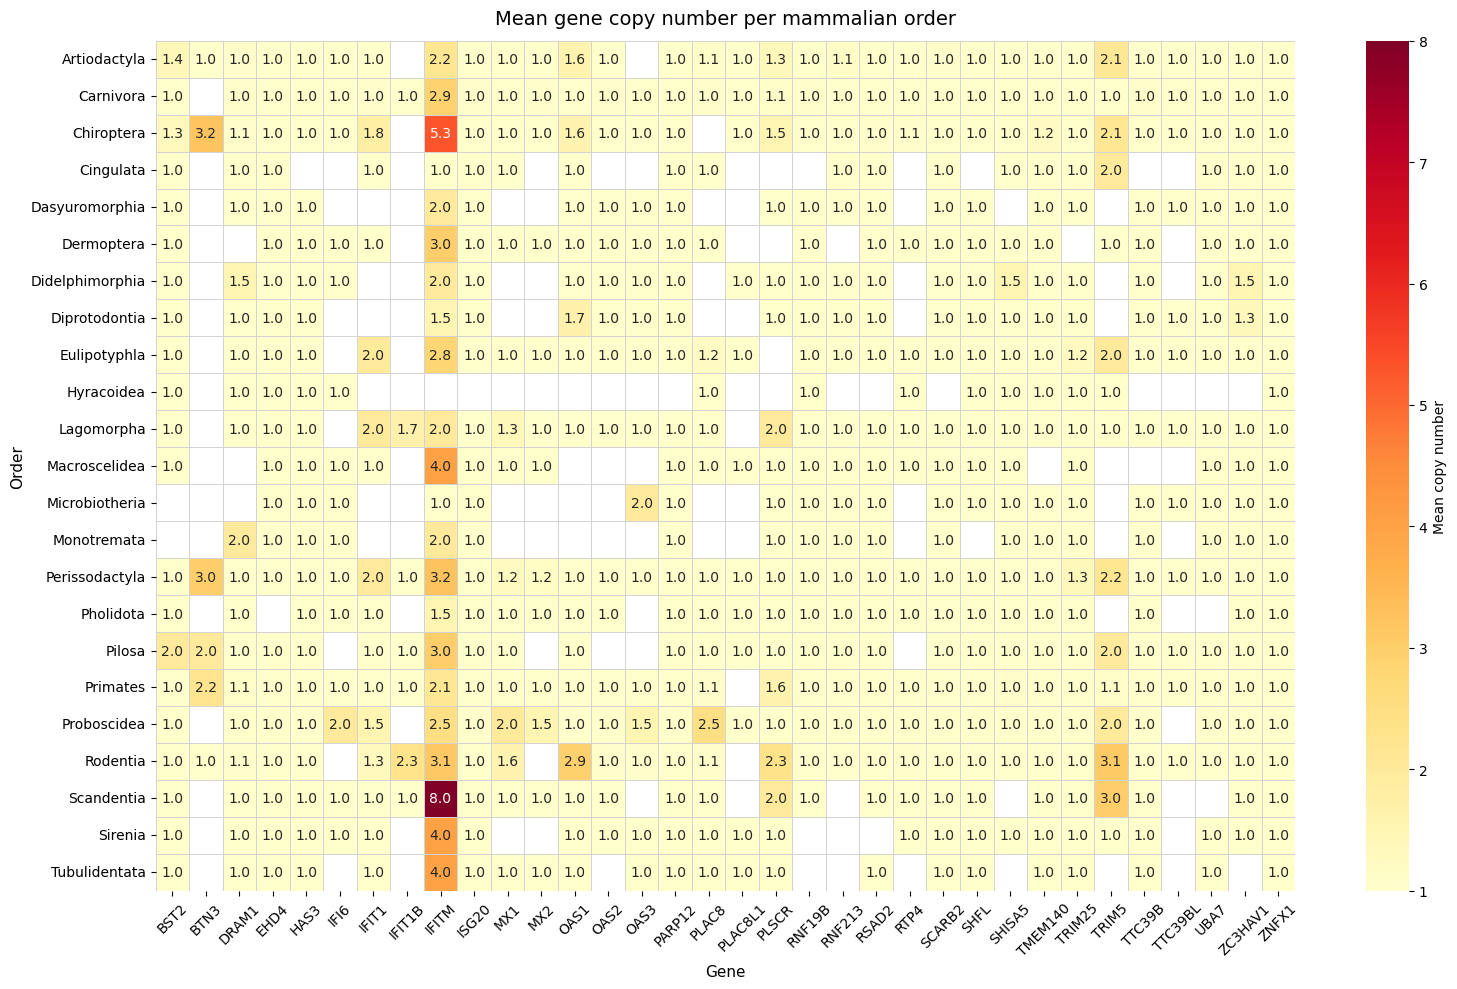

In [36]:
plot_gene_copy_heatmap(df_gene_copies_melted)

# Extract number of genome assemblies per species from NCBI

In [1]:
import subprocess
import json
import csv
import sys

In [ ]:
def run_command(cmd):
    try:
        subprocess.run(cmd, check=True)
    except subprocess.CalledProcessError as e:
        print(f"Command failed: {' '.join(cmd)}", file=sys.stderr)
        sys.exit(1)


def get_mammalian_assemblies(output_tsv="../additional_files/ncbi_mammalian_genome_assemblies/mammalian_genbank_assemblies.tsv"):
    jsonl_file = "../additional_files/ncbi_mammalian_genome_assemblies/mammalia.jsonl"

    # Step 1: fetch assembly metadata
    datasets_cmd = [
        "datasets",
        "summary",
        "genome",
        "taxon",
        "Mammalia",
        "--assembly-source", "GenBank",
        "--assembly-version", "latest",
        "--as-json-lines"
    ]

    with open(jsonl_file, "w") as out:
        try:
            subprocess.run(datasets_cmd, stdout=out, check=True)
        except subprocess.CalledProcessError:
            print("datasets command failed", file=sys.stderr)
            sys.exit(1)

    # Step 2: flatten metadata
    dataformat_cmd = [
        "dataformat",
        "tsv",
        "genome",
        "--inputfile", jsonl_file,
        "--fields",
        "accession,organism-name,organism-tax-id,assminfo-level,annotinfo-status"
    ]

    with open(output_tsv, "w") as out:
        try:
            subprocess.run(dataformat_cmd, stdout=out, check=True)
        except subprocess.CalledProcessError:
            print("dataformat command failed", file=sys.stderr)
            sys.exit(1)

    print(f"Saved output to {output_tsv}")

In [5]:
get_mammalian_assemblies()

Saved output to mammalian_genbank_assemblies.tsv


In [6]:
import json
import pandas as pd

def parse_mammalia_jsonl(jsonl_file):
    """
    Parse NCBI Datasets genome summary JSONL file and extract:
      - assembly accession
      - species
      - taxid
      - assembly level
      - annotation status

    Parameters
    ----------
    jsonl_file : str
        Path to mammalia.jsonl

    Returns
    -------
    pandas.DataFrame
    """

    records = []

    with open(jsonl_file, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                continue

            accession = (
                record.get("accession")
                or record.get("current_accession")
                or ""
            )

            organism = record.get("organism", {})
            species = organism.get("organism_name", "")
            taxid = organism.get("tax_id", "")

            assembly_info = record.get("assembly_info", {})
            assembly_level = assembly_info.get("assembly_level", "")

            # Annotation info:
            # True if RefSeq paired assembly / annotation exists
            paired = record.get("paired_accession", "")
            annotation_info = bool(paired)

            records.append({
                "assembly_accession": accession,
                "species": species,
                "taxid": taxid,
                "assembly_level": assembly_level,
                "annotation_status": annotation_info
            })

    df = pd.DataFrame(records)

    return df

In [ ]:
# Example usage
df = parse_mammalia_jsonl("../additional_files/ncbi_mammalian_genome_assemblies/mammalia.jsonl")
print(f"Parsed {len(df)} assemblies")

In [8]:
df

,assembly_accession,species,taxid,assembly_level,annotation_status
0,GCA_001443585.1,Acinonyx jubatus,32536,Scaffold,True
1,GCA_003709585.1,Acinonyx jubatus,32536,Scaffold,True
2,GCA_027475565.2,Acinonyx jubatus,32536,Chromosome,True
3,GCA_029890205.1,Acomys cahirinus,10068,Chromosome,False
4,GCA_004027535.1,Acomys cahirinus,10068,Scaffold,False
...,...,...,...,...,...
4746,GCA_009762295.2,Zalophus californianus,9704,Contig,False
4747,GCA_009762305.2,Zalophus californianus,9704,Chromosome,True
4748,GCA_900631625.1,Zalophus californianus,9704,Scaffold,True
4749,GCA_004024765.1,Zapus hudsonius,160400,Scaffold,False


In [12]:
from ete3 import NCBITaxa

# Initialize local NCBI taxonomy database
ncbi = NCBITaxa()


def get_mammalian_order(taxid):
    """
    Get mammalian order for a given taxid.

    Parameters
    ----------
    taxid : int or str

    Returns
    -------
    str or None
    """
    try:
        taxid = int(taxid)

        lineage = ncbi.get_lineage(taxid)
        ranks = ncbi.get_rank(lineage)
        names = ncbi.get_taxid_translator(lineage)

        for lineage_taxid in lineage:
            if ranks.get(lineage_taxid) == "order":
                return names.get(lineage_taxid)

    except Exception:
        return None

    return None


def add_order_column(df):
    """
    Add mammalian order column to DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain 'taxid'

    Returns
    -------
    pandas.DataFrame
    """
    df = df.copy()

    # unique taxids for faster lookup
    unique_taxids = df["taxid"].dropna().unique()

    order_map = {
        taxid: get_mammalian_order(taxid)
        for taxid in unique_taxids
    }

    df["order"] = df["taxid"].map(order_map)

    return df

In [13]:
# Example usage:
df = add_order_column(df)

In [ ]:
df

,assembly_accession,species,taxid,assembly_level,annotation_status,order
0,GCA_001443585.1,Acinonyx jubatus,32536,Scaffold,True,Carnivora
1,GCA_003709585.1,Acinonyx jubatus,32536,Scaffold,True,Carnivora
2,GCA_027475565.2,Acinonyx jubatus,32536,Chromosome,True,Carnivora
3,GCA_029890205.1,Acomys cahirinus,10068,Chromosome,False,Rodentia
4,GCA_004027535.1,Acomys cahirinus,10068,Scaffold,False,Rodentia
...,...,...,...,...,...,...
4746,GCA_009762295.2,Zalophus californianus,9704,Contig,False,Carnivora
4747,GCA_009762305.2,Zalophus californianus,9704,Chromosome,True,Carnivora
4748,GCA_900631625.1,Zalophus californianus,9704,Scaffold,True,Carnivora
4749,GCA_004024765.1,Zapus hudsonius,160400,Scaffold,False,Rodentia


In [ ]:
df.to_csv('../additional_files/ncbi_mammalian_genome_assemblies/mammalian_genbank_assemblies.tsv', index=False, sep='\t')

In [17]:
# Example usage:
df_best = filter_and_select_best_assembly_df(
    df,
    min_level="Scaffold",
    require_annotation=False
)
print(f"Retained {len(df_best)} representative species assemblies")

Retained 975 representative species assemblies


In [18]:
df_best

,assembly_accession,species,taxid,assembly_level,annotation_status,order
0,GCA_027475565.2,Acinonyx jubatus,32536,Chromosome,True,Carnivora
1,GCA_029890205.1,Acomys cahirinus,10068,Chromosome,False,Rodentia
2,GCA_907164435.1,Acomys dimidiatus,60744,Chromosome,False,Rodentia
3,GCA_907164505.1,Acomys kempi,83762,Chromosome,False,Rodentia
4,GCA_964271855.5,Acomys minous,83528,Chromosome,False,Rodentia
...,...,...,...,...,...,...
970,GCA_004024805.1,Xerus inauris,234690,Scaffold,False,Rodentia
971,GCA_028644305.1,Xerus rutilus,226860,Chromosome,False,Rodentia
972,GCA_009762305.2,Zalophus californianus,9704,Chromosome,True,Carnivora
973,GCA_004024765.1,Zapus hudsonius,160400,Scaffold,False,Rodentia


In [19]:
df_best['order'].value_counts()

order
Primates            251
Artiodactyla        193
Rodentia            168
Chiroptera          118
Carnivora           114
Eulipotyphla         23
Perissodactyla       17
Lagomorpha           16
Diprotodontia        16
Dasyuromorphia        9
Pholidota             8
Pilosa                6
Afrosoricida          5
Cingulata             4
Sirenia               4
Proboscidea           4
Macroscelidea         2
Didelphimorphia       2
Dermoptera            2
Scandentia            2
Hyracoidea            2
Peramelemorphia       2
Monotremata           2
Tubulidentata         2
Microbiotheria        1
Paucituberculata      1
Notoryctemorphia      1
Name: count, dtype: int64